# Entrega final — Modelo congelado (regresión logística, escenario B)

Machine Learning I · Universidad Externado de Colombia

Cuaderno autocontenido: todo el flujo está en estas celdas (estilo Colab). Las decisiones congeladas están en `documentacion/contrato_decisiones.md` del paquete de entrega.

Qué hace este cuaderno
1. Carga `database.csv`, deduplica y parte train/test (80/20, semilla 42).
2. Repite la CV de la 2.ª entrega (logística, LDA, KNN, Naive Bayes; escenarios A/B/C).
3. Calcula probabilidades OOF (validación cruzada en entrenamiento) y fija umbrales (0,5, Youden, costos con r = 1, 2, 5).
4. Entrena el pipeline final escenario B y guarda `pipeline_logistica_B.joblib`.
5. Reporta test en modo solo lectura (sin optimizar umbrales en prueba).

Qué no hace
- No usa el conjunto de prueba para elegir modelo ni umbral.
- No reabre QDA, Ridge ni Lasso.

Colab: suba `database.csv` a `/content/` o `/content/datos/`. En local, déjelo en `datos/database.csv` respecto a la raíz del paquete (`Entrega_final_ML/`).

Scores: `predict_proba[:, 1]` es un índice de riesgo relativo para ordenar clientes en una muestra similar, no probabilidad de mora en el mercado peruano.


In [1]:
# --- 0. Imports ---
from pathlib import Path
import json
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [2]:
# --- 0.1 Rutas (local, Colab o Jupyter desde codigo/tercera) ---

def find_project_dirs():
    candidatos_base = [Path.cwd(), *Path.cwd().parents]
    for base in candidatos_base:
        if (base / "datos" / "database.csv").exists():
            codigo = base / "codigo" if (base / "codigo").is_dir() else base
            return base, codigo
    for p in (
        Path("/content"),
        Path.cwd(),
    ):
        for rel in ("database.csv", "datos/database.csv"):
            if (p / rel).exists():
                proyecto = p if rel == "datos/database.csv" else p.parent
                if not (proyecto / "datos" / "database.csv").exists() and (p / "database.csv").exists():
                    proyecto = p
                codigo = proyecto / "codigo" if (proyecto / "codigo").is_dir() else proyecto
                return proyecto, codigo
    raise FileNotFoundError(
        "No encontré database.csv. En Colab: Files → subir a /content. "
        "En local: datos/database.csv en la raíz del proyecto."
    )


PROYECTO_DIR, CODIGO_DIR = find_project_dirs()
OUT_DIR = CODIGO_DIR / "salidas_tercera"
INFORME_DIR = PROYECTO_DIR / "documentacion" / "tercera_entrega" / "entregables_para_informe"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Proyecto:", PROYECTO_DIR.resolve())
print("Salidas:", OUT_DIR.resolve())
print("Informe (figuras):", INFORME_DIR.resolve() if INFORME_DIR.parent.exists() else "(opcional)")


Proyecto: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto
Salidas: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\codigo\salidas_tercera
Informe (figuras): C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\documentacion\tercera_entrega\entregables_para_informe


In [3]:
# --- 1. Constantes (contrato de decisiones) ---
SEED = 42
NUM_ALL = [
    "edad", "dias_lab", "exp_sf", "nivel_ahorro", "ingreso", "linea_sf",
    "deuda_sf", "score", "atraso", "clasif_sbs",
]
CAT_ALL = ["vivienda", "zona", "nivel_educ"]
ESC_PRINCIPAL_KEY = "B. Principal (sin atraso ni clasif_sbs)"
ESCENARIOS = {
    "A. Completo (13 variables)": [c for c in NUM_ALL + CAT_ALL],
    ESC_PRINCIPAL_KEY: [c for c in NUM_ALL + CAT_ALL if c not in ("atraso", "clasif_sbs")],
    "C. Conservador (sin atraso, clasif_sbs ni score)": [
        c for c in NUM_ALL + CAT_ALL if c not in ("atraso", "clasif_sbs", "score")
    ],
}
K_LISTA = [5, 11, 21, 31, 51, 101, 151, 201]
MODELO_FINAL = LogisticRegression(C=1e6, max_iter=5000)
cols_b = ESCENARIOS[ESC_PRINCIPAL_KEY]
print("Modelo final: logística | Escenario B:", cols_b)


Modelo final: logística | Escenario B: ['edad', 'dias_lab', 'exp_sf', 'nivel_ahorro', 'ingreso', 'linea_sf', 'deuda_sf', 'score', 'vivienda', 'zona', 'nivel_educ']


## 2. Funciones auxiliares (pipeline, métricas, umbrales)

Mismo diseño que la 2.ª entrega: imputación mediana + indicador, escalado, one-hot con categorías infrecuentes, sin balanceo en el modelo final.


In [4]:
def resolve_data_path():
    for base in [PROYECTO_DIR, Path.cwd(), *Path.cwd().parents]:
        p = base / "datos" / "database.csv"
        if p.exists():
            return p
    for p in (
        Path("datos/database.csv"),
        Path("../datos/database.csv"),
        Path("../../datos/database.csv"),
        Path("/content/database.csv"),
        Path("/content/datos/database.csv"),
    ):
        if p.exists():
            return p
    raise FileNotFoundError("database.csv no encontrado")


def construir_pipeline(cols, modelo, muestreo=None):
    num = [c for c in cols if c in NUM_ALL]
    cat = [c for c in cols if c in CAT_ALL]
    prep = ColumnTransformer(
        [
            (
                "num",
                Pipeline([
                    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                    ("esc", StandardScaler()),
                ]),
                num,
            ),
            (
                "cat",
                OneHotEncoder(
                    drop="first",
                    min_frequency=50,
                    handle_unknown="infrequent_if_exist",
                    sparse_output=False,
                ),
                cat,
            ),
        ]
    )
    pasos = [("prep", prep)]
    if muestreo is not None:
        pasos.append(("muestreo", muestreo))
    pasos.append(("modelo", modelo))
    return ImbPipeline(pasos)


def metricas_en_umbral(y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "umbral": t,
        "sensibilidad_TPR": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "especificidad_TNR": recall_score(y_true, pred, pos_label=0, zero_division=0),
        "precision_mora1": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "FN": int(fn),
        "FP": int(fp),
        "VP": int(tp),
        "VN": int(tn),
    }


def umbral_youden(y_true, proba):
    ts = np.linspace(0.05, 0.95, 181)
    mejor_t, mejor_j = 0.5, -1.0
    for t in ts:
        m = metricas_en_umbral(y_true, proba, t)
        j = m["sensibilidad_TPR"] + m["especificidad_TNR"] - 1
        if j > mejor_j:
            mejor_j, mejor_t = j, t
    return float(mejor_t), float(mejor_j)


def umbral_costo(y_true, proba, ratio_fn_fp):
    ts = np.linspace(0.05, 0.95, 181)
    mejor_t, mejor_c = 0.5, np.inf
    for t in ts:
        m = metricas_en_umbral(y_true, proba, t)
        costo = ratio_fn_fp * m["FN"] + m["FP"]
        if costo < mejor_c:
            mejor_c, mejor_t = costo, t
    return float(mejor_t), float(mejor_c)


def cv_cuatro_modelos(X_tr, y_tr, cols):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    auc_k = {
        k: cross_validate(
            construir_pipeline(cols, KNeighborsClassifier(k)),
            X_tr[cols], y_tr, cv=cv, scoring={"roc": "roc_auc"},
        )["test_roc"]
        for k in K_LISTA
    }
    k_mejor = max(auc_k, key=lambda k: auc_k[k].mean())
    modelos = {
        "Regresión logística": MODELO_FINAL,
        "LDA": LinearDiscriminantAnalysis(),
        "KNN": KNeighborsClassifier(k_mejor),
        "Naive Bayes": GaussianNB(),
    }
    filas = []
    for nombre, m in modelos.items():
        r = cross_validate(
            construir_pipeline(cols, m),
            X_tr[cols], y_tr, cv=cv,
            scoring={"roc": "roc_auc", "pr": "average_precision"},
        )
        filas.append({
            "Modelo": nombre,
            "ROC-AUC CV (media)": round(r["test_roc"].mean(), 3),
            "ROC-AUC CV (desv.)": round(r["test_roc"].std(), 3),
            "PR-AUC CV (media)": r["test_pr"].mean(),
            "PR-AUC CV (desv.)": r["test_pr"].std(),
            "Hiperparámetro elegido": f"k = {k_mejor}" if nombre == "KNN" else "—",
        })
    return pd.DataFrame(filas), k_mejor


def cv_escenarios_abc(X_tr, y_tr):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    filas = []
    for nom, cols in ESCENARIOS.items():
        r = cross_validate(
            construir_pipeline(cols, MODELO_FINAL),
            X_tr[cols], y_tr, cv=cv, scoring={"roc": "roc_auc"},
        )
        filas.append({"Escenario": nom, "AUC CV (logística)": round(r["test_roc"].mean(), 3)})
    return pd.DataFrame(filas)


## 3. Datos y partición (igual que 2.ª entrega)


In [5]:
np.random.seed(SEED)
data_path = resolve_data_path()
df_raw = pd.read_csv(data_path)
df = df_raw.drop_duplicates().reset_index(drop=True)
X_full = df.drop(columns="mora")
y = df["mora"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_full, y, test_size=0.20, stratify=y, random_state=SEED,
)
print("Archivo:", data_path)
print("Clientes únicos:", len(df), "| Train:", len(y_tr), "| Test:", len(y_te))
print("Prevalencia mora (train):", round(100 * y_tr.mean(), 1), "%")


Archivo: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\datos\database.csv
Clientes únicos: 6074 | Train: 4859 | Test: 1215
Prevalencia mora (train): 71.0 %


## 4. Validación cruzada — comparación de modelos (histórica)

Documenta por qué el modelo final sigue siendo **regresión logística** en escenario B. No es una nueva competición en test.


In [6]:
tabla_cv, k_mejor = cv_cuatro_modelos(X_tr, y_tr, cols_b)
tabla_cv_esc = cv_escenarios_abc(X_tr, y_tr)
tabla_cv.to_csv(OUT_DIR / "tabla_cv_modelo_final.csv", index=False)
tabla_cv_esc.to_csv(OUT_DIR / "tabla_cv_escenarios_abc.csv", index=False)
display(tabla_cv)
display(tabla_cv_esc)
print("KNN — k elegido en CV:", k_mejor)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


... (3 outputs left out)

C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


,Modelo,ROC-AUC CV (media),ROC-AUC CV (desv.),PR-AUC CV (media),PR-AUC CV (desv.),Hiperparámetro elegido
0,Regresión logística,0.698,0.017,0.835298,0.013451,—
1,LDA,0.699,0.017,0.834548,0.013393,—
2,KNN,0.689,0.015,0.827428,0.005666,k = 151
3,Naive Bayes,0.657,0.012,0.805696,0.011070,—


,Escenario,AUC CV (logística)
0,A. Completo (13 variables),0.715
1,B. Principal (sin atraso ni clasif_sbs),0.698
2,"C. Conservador (sin atraso, clasif_sbs ni score)",0.692


KNN — k elegido en CV: 151


## 5. Umbrales con predicciones OOF (solo entrenamiento)

$C = r \cdot FN + FP$. Los cortes se buscan en la grilla de umbrales sobre probabilidades OOF (`cross_val_predict`, 5 folds). **Línea base:** predecir siempre mora (FN=0, FP = buenos pagadores en train).


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe_oof = construir_pipeline(cols_b, MODELO_FINAL)
proba_oof = cross_val_predict(pipe_oof, X_tr[cols_b], y_tr, cv=cv, method="predict_proba")[:, 1]

t_youden, j_youden = umbral_youden(y_tr, proba_oof)
t_c1, cost_c1 = umbral_costo(y_tr, proba_oof, 1.0)
t_c2, cost_c2 = umbral_costo(y_tr, proba_oof, 2.0)
t_c5, cost_c5 = umbral_costo(y_tr, proba_oof, 5.0)

n_buenos = int((y_tr == 0).sum())
baseline_fp = n_buenos
baseline_cost = {1: baseline_fp, 2: baseline_fp, 5: baseline_fp}

print("Youden t =", round(t_youden, 3), "| J =", round(j_youden, 3))
print("Costo mín. r=1 → t =", round(t_c1, 3), "C =", round(cost_c1, 0))
print("Costo mín. r=2 → t =", round(t_c2, 3), "C =", round(cost_c2, 0))
print("Costo mín. r=5 → t =", round(t_c5, 3), "C =", round(cost_c5, 0))
print("Línea base FP (OOF):", baseline_fp)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Youden t = 0.71 | J = 0.298
Costo mín. r=1 → t = 0.57 C = 1302.0
Costo mín. r=2 → t = 0.27 C = 1392.0
Costo mín. r=5 → t = 0.135 C = 1404.0
Línea base FP (OOF): 1409


In [8]:
ts = np.linspace(0.05, 0.95, 181)
filas_umbral = []
for t in ts:
    m = metricas_en_umbral(y_tr, proba_oof, t)
    m["costo_ratio1"] = m["FN"] + m["FP"]
    m["costo_ratio2"] = 2 * m["FN"] + m["FP"]
    m["costo_ratio5"] = 5 * m["FN"] + m["FP"]
    m["J_youden"] = m["sensibilidad_TPR"] + m["especificidad_TNR"] - 1
    filas_umbral.append(m)
df_umbral = pd.DataFrame(filas_umbral)
df_umbral.to_csv(OUT_DIR / "tabla_umbral_costos_oof.csv", index=False)


def fila_costo(etiqueta, t, m):
    out = {**m, "escenario": etiqueta, "umbral": t}
    out["C_r1"] = m["FN"] + m["FP"]
    out["C_r2"] = 2 * m["FN"] + m["FP"]
    out["C_r5"] = 5 * m["FN"] + m["FP"]
    return out


baseline_m = metricas_en_umbral(y_tr, np.ones_like(proba_oof), 0.5)
baseline_m["FN"], baseline_m["FP"] = 0, baseline_fp

destacados = [
    fila_costo("linea_base_siempre_mora", np.nan, baseline_m),
    fila_costo("convencion_0.5", 0.5, metricas_en_umbral(y_tr, proba_oof, 0.5)),
    fila_costo("youden_oof", t_youden, metricas_en_umbral(y_tr, proba_oof, t_youden)),
    fila_costo("costo_FN_1x_FP", t_c1, metricas_en_umbral(y_tr, proba_oof, t_c1)),
    fila_costo("costo_FN_2x_FP", t_c2, metricas_en_umbral(y_tr, proba_oof, t_c2)),
    fila_costo("costo_FN_5x_FP", t_c5, metricas_en_umbral(y_tr, proba_oof, t_c5)),
]
df_dest = pd.DataFrame(destacados)
df_dest.to_csv(OUT_DIR / "tabla_umbrales_destacados_oof.csv", index=False)

comite = df_dest[
    ["escenario", "umbral", "FN", "FP", "sensibilidad_TPR", "especificidad_TNR", "C_r1", "C_r2", "C_r5"]
].copy()
for r in (1, 2, 5):
    comite[f"linea_base_C_r{r}"] = baseline_cost[r]
comite.to_csv(OUT_DIR / "tabla_umbral_costos_comite_oof.csv", index=False)

display(df_dest.round(3))


,umbral,sensibilidad_TPR,especificidad_TNR,precision_mora1,FN,FP,VP,VN,escenario,C_r1,C_r2,C_r5
0,NaN,1.000,0.000,0.710,0,1409,3450,0,linea_base_siempre_mora,1409,1409,1409
1,0.500,0.929,0.236,0.749,244,1076,3206,333,convencion_0.5,1320,1564,2296
2,0.710,0.684,0.614,0.813,1090,544,2360,865,youden_oof,1634,2724,5994
3,0.570,0.890,0.346,0.769,381,921,3069,488,costo_FN_1x_FP,1302,1683,2826
4,0.270,0.996,0.031,0.716,13,1366,3437,43,costo_FN_2x_FP,1379,1392,1431
5,0.135,1.000,0.004,0.711,0,1404,3450,5,costo_FN_5x_FP,1404,1404,1404


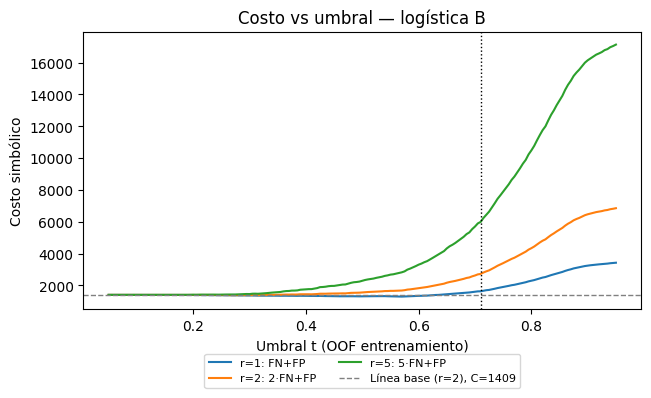

{
  "t_convencion": 0.5,
  "t_youden_oof": 0.71,
  "t_costo_fn_1x_fp_oof": 0.57,
  "t_costo_fn_2x_fp_oof": 0.27,
  "t_costo_fn_5x_fp_oof": 0.135,
  "j_youden_oof": 0.298,
  "costo_simbolico_oof_ratio1": 1302.0,
  "costo_simbolico_oof_ratio2": 1392.0,
  "costo_simbolico_oof_ratio5": 1404.0,
  "linea_base_FP_oof": 1409,
  "linea_base_costo_r1": 1409,
  "nota": "Umbrales elegidos solo con OOF en entrenamiento. No optimizar en test."
}


In [9]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(df_umbral["umbral"], df_umbral["costo_ratio1"], label="r=1: FN+FP")
ax.plot(df_umbral["umbral"], df_umbral["costo_ratio2"], label="r=2: 2·FN+FP")
ax.plot(df_umbral["umbral"], df_umbral["costo_ratio5"], label="r=5: 5·FN+FP")
ax.axhline(baseline_cost[2], color="gray", ls="--", lw=1, label=f"Línea base (r=2), C={baseline_cost[2]}")
ax.axvline(t_youden, color="black", ls=":", lw=1)
ax.set_xlabel("Umbral t (OOF entrenamiento)")
ax.set_ylabel("Costo simbólico")
ax.set_title("Costo vs umbral — logística B")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
fig.subplots_adjust(bottom=0.22)
fig.savefig(OUT_DIR / "fig_costo_vs_umbral.png", dpi=140)
plt.show()

umbrales = {
    "t_convencion": 0.5,
    "t_youden_oof": round(t_youden, 4),
    "t_costo_fn_1x_fp_oof": round(t_c1, 4),
    "t_costo_fn_2x_fp_oof": round(t_c2, 4),
    "t_costo_fn_5x_fp_oof": round(t_c5, 4),
    "j_youden_oof": round(j_youden, 4),
    "costo_simbolico_oof_ratio1": round(cost_c1, 1),
    "costo_simbolico_oof_ratio2": round(cost_c2, 1),
    "costo_simbolico_oof_ratio5": round(cost_c5, 1),
    "linea_base_FP_oof": baseline_fp,
    "linea_base_costo_r1": baseline_cost[1],
    "nota": "Umbrales elegidos solo con OOF en entrenamiento. No optimizar en test.",
}
(OUT_DIR / "umbrales_recomendados.json").write_text(
    json.dumps(umbrales, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(umbrales, indent=2, ensure_ascii=False))


## 6. Modelo final — ajuste en todo el train y serialización

Objeto que consume **Streamlit** (`pipeline_logistica_B.joblib`). Mismas 11 variables, sin balanceo.


In [10]:
pipe_final = construir_pipeline(cols_b, MODELO_FINAL)
pipe_final.fit(X_tr[cols_b], y_tr)
joblib.dump(pipe_final, OUT_DIR / "pipeline_logistica_B.joblib")

config = {
    "modelo": "LogisticRegression(C=1e6, max_iter=5000)",
    "escenario": ESC_PRINCIPAL_KEY,
    "variables": cols_b,
    "balanceo": "ninguno",
    "semilla": SEED,
    "particion": "80/20 estratificada",
    "k_knn_referencia_cv": int(k_mejor),
}
(OUT_DIR / "configuracion_definitiva.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)
pd.DataFrame([config]).to_csv(OUT_DIR / "tabla_configuracion_definitiva.csv", index=False)
display(pd.DataFrame([config]))
print("Guardado:", OUT_DIR / "pipeline_logistica_B.joblib")


,modelo,escenario,variables,balanceo,semilla,particion,k_knn_referencia_cv
0,"LogisticRegression(C=1e6, max_iter=5000)",B. Principal (sin atraso ni clasif_sbs),"[edad, dias_lab, exp_sf, nivel_ahorro, ingreso...",ninguno,42,80/20 estratificada,151


Guardado: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\codigo\salidas_tercera\pipeline_logistica_B.joblib


## 7. Conjunto de prueba — **solo lectura**

Copiamos la tabla de cierre de la 2.ª entrega, verificamos AUC reentrenado y aplicamos umbrales **ya fijados en OOF**.


In [11]:
ref_test = CODIGO_DIR / "salidas_segunda" / "tabla_test_principal.csv"
if ref_test.exists():
    pd.read_csv(ref_test).to_csv(OUT_DIR / "tabla_test_cierre_segunda_entrega.csv", index=False)
else:
    print("Aviso: no hay", ref_test, "— omito copia 2.ª entrega")

proba_te = pipe_final.predict_proba(X_te[cols_b])[:, 1]
auc_verify = roc_auc_score(y_te, proba_te)
verif = pd.DataFrame([
    {
        "AUC_reentrenado_mismo_train_test": round(auc_verify, 3),
        "AUC_informe_segunda_entrega": 0.722,
        "uso": "Verificación. No usar test para elegir modelo ni umbral.",
    }
])
verif.to_csv(OUT_DIR / "tabla_test_verificacion_solo_lectura.csv", index=False)

filas_te = []
for etiqueta, tval in [
    ("convencion_0.5", 0.5),
    ("youden_oof", umbrales["t_youden_oof"]),
    ("costo_FN_1x_FP_oof", umbrales["t_costo_fn_1x_fp_oof"]),
    ("costo_FN_2x_FP_oof", umbrales["t_costo_fn_2x_fp_oof"]),
    ("costo_FN_5x_FP_oof", umbrales["t_costo_fn_5x_fp_oof"]),
]:
    m = metricas_en_umbral(y_te, proba_te, tval)
    m["escenario_umbral"] = etiqueta
    filas_te.append(m)
pd.DataFrame(filas_te).to_csv(OUT_DIR / "tabla_test_umbrales_solo_lectura.csv", index=False)

resumen = pd.DataFrame([
    {"clave": "n_train", "valor": len(y_tr)},
    {"clave": "n_test", "valor": len(y_te)},
    {"clave": "pct_mora", "valor": round(100 * y_tr.mean(), 1)},
    {"clave": "auc_cv_logistica", "valor": tabla_cv.loc[0, "ROC-AUC CV (media)"]},
])
resumen.to_csv(OUT_DIR / "resumen_ejecucion.csv", index=False)

display(verif)
display(pd.read_csv(OUT_DIR / "tabla_test_umbrales_solo_lectura.csv").round(3))


,AUC_reentrenado_mismo_train_test,AUC_informe_segunda_entrega,uso
0,0.722,0.722,Verificación. No usar test para elegir modelo ...


,umbral,sensibilidad_TPR,especificidad_TNR,precision_mora1,FN,FP,VP,VN,escenario_umbral
0,0.500,0.942,0.247,0.754,50,265,813,87,convencion_0.5
1,0.710,0.689,0.634,0.822,268,129,595,223,youden_oof
2,0.570,0.905,0.349,0.773,82,229,781,123,costo_FN_1x_FP_oof
3,0.270,0.995,0.051,0.720,4,334,859,18,costo_FN_2x_FP_oof
4,0.135,1.000,0.000,0.710,0,352,863,0,costo_FN_5x_FP_oof


## 8. Copia de archivos para el informe

Si existe la carpeta `documentacion/entregables_para_informe/`, replica tablas y figuras para compilar el PDF. En Colab puede omitirse.


In [12]:
ARTEFACTOS = [
    "tabla_cv_modelo_final.csv",
    "tabla_cv_escenarios_abc.csv",
    "tabla_umbral_costos_oof.csv",
    "tabla_umbrales_destacados_oof.csv",
    "tabla_umbral_costos_comite_oof.csv",
    "fig_costo_vs_umbral.png",
    "umbrales_recomendados.json",
    "pipeline_logistica_B.joblib",
    "configuracion_definitiva.json",
    "tabla_configuracion_definitiva.csv",
    "tabla_test_cierre_segunda_entrega.csv",
    "tabla_test_verificacion_solo_lectura.csv",
    "tabla_test_umbrales_solo_lectura.csv",
    "resumen_ejecucion.csv",
]

if INFORME_DIR.parent.exists():
    INFORME_DIR.mkdir(parents=True, exist_ok=True)
    for nombre in ARTEFACTOS:
        src = OUT_DIR / nombre
        if src.exists():
            shutil.copy2(src, INFORME_DIR / nombre)
    print("Copiados →", INFORME_DIR.resolve())
else:
    print("Carpeta informe no encontrada; salidas solo en", OUT_DIR)


Copiados → C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\documentacion\tercera_entrega\entregables_para_informe
